# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# Convenção de cores do laboratório
COR_NEUTRA = "lightgray"     # Fundo neutro e distribuições agregadas
COR_CONTEXTO = "#38bdf8"    # Azul celeste para classe de referência (Saudável)
COR_DESTAQUE = "#7c3aed"    # Roxo/violeta para classe de interesse (Degradada/Falha)
COR_ALERTA = "#ef4444"      # Vermelho para anomalias e outliers

## Carregando o Dataset

In [ ]:
import os
import glob
import kagglehub
import pandas as pd

# Baixa todos os arquivos do dataset para o cache local
path = kagglehub.dataset_download("srisyra02/ev-battery-health-prediction-dataset-20k")
print("Arquivos baixados em:", path)

# Encontra o arquivo CSV automaticamente dentro da pasta
csv_files = glob.glob(os.path.join(path, "*.csv"))

if csv_files:
    df = pd.read_csv(csv_files[0])
    print(f"Carregado com sucesso: {os.path.basename(csv_files[0])}")
    display(df.head())

Using Colab cache for faster access to the 'ev-battery-health-prediction-dataset-20k' dataset.
Arquivos baixados em: /kaggle/input/ev-battery-health-prediction-dataset-20k
Carregado com sucesso: ev battery_failure prediction Dataset.csv


,vehicle_id,vehicle_brand,vehicle_model,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,odometer_km,...,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
0,EV100000,Ford,Mustang Mach-E,Truck,2022.0,Northvolt,NMC,NaN,AWD,290844.3,...,1.0,NaN,0.0,30.37,73.05,98.14,89.73,47.11,6748.0,0
1,EV100001,Tata,Tiago EV,Truck,2017.0,CATL,NCA,38.71,RWD,182239.5,...,0.0,1.0,0.0,67.94,82.50,NaN,NaN,55.38,5211.0,0
2,EV100002,Volkswagen,ID.3,Crossover,2016.0,BYD Battery,LFP,131.29,FWD,249369.3,...,0.0,1.0,0.0,74.84,90.33,60.02,86.84,74.54,4040.0,0
3,EV100003,NaN,Kona Electric,Sedan,2019.0,SK On,NMC,132.35,FWD,134830.2,...,NaN,0.0,0.0,46.94,56.69,66.43,93.93,31.69,NaN,0
4,EV100004,MG,ZS EV,SUV,2017.0,Guoxuan,LTO,25.72,AWD,158026.0,...,1.0,2.0,3.0,49.07,73.65,95.05,100.00,23.46,7290.0,0


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

Antes de rodar: o EV Battery Health Prediction Dataset reúne diversas variáveis preditoras que monitoram o ciclo de vida e a física operacional do veículo (como ciclos de carga, temperatura da bateria, resistência interna, quilometragem no hodômetro e capacidade nominal em kWh) além do atributo alvo (battery_health/battery_failure, indicando o estado de integridade ou falha da célula).

### Dimensão e Tipos de ...

Inspecionamos o tamanho dimensional da matriz de telemetria e o tipo primitivo de cada uma das 57+ colunas.

In [ ]:
df.shape

(20000, 70)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 70 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   vehicle_id                       20000 non-null  object 
 1   vehicle_brand                    19356 non-null  object 
 2   vehicle_model                    19180 non-null  object 
 3   vehicle_type                     19356 non-null  object 
 4   manufacturing_year               19018 non-null  float64
 5   battery_manufacturer             19382 non-null  object 
 6   battery_chemistry                19278 non-null  object 
 7   battery_capacity_kwh             19310 non-null  float64
 8   drive_type                       19274 non-null  object 
 9   odometer_km                      19134 non-null  float64
 10  vehicle_age_years                19232 non-null  float64
 11  fleet_or_private                 19106 non-null  object 
 12  battery_serial    

In [ ]:
df.describe()

,manufacturing_year,battery_capacity_kwh,odometer_km,vehicle_age_years,cycle_count,battery_health_percent,state_of_charge,depth_of_discharge,state_of_health,cell_voltage_avg,...,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
count,19018.000000,19310.000000,19134.000000,19232.000000,19234.000000,19102.000000,19036.000000,19168.000000,19044.000000,19060.000000,...,19032.000000,19094.000000,19240.000000,19270.000000,19164.000000,19368.00000,19282.000000,19320.000000,19102.000000,20000.0000
mean,2019.491482,87.124810,169562.067362,6.507302,1358.999584,81.911451,50.940556,44.429334,81.881542,3.597902,...,0.702449,1.206452,0.597401,47.380257,61.780447,80.64006,87.266611,40.446050,7825.358287,0.0692
std,2.864259,35.831323,74761.687034,2.882844,529.597491,8.991068,28.290460,17.035009,9.108197,0.126524,...,0.836291,1.090139,0.768265,12.722088,22.099914,15.29981,8.502523,13.266399,1680.547458,0.2538
min,2015.000000,25.000000,500.000000,1.370000,173.000000,47.030000,2.000000,5.230000,47.770000,3.061000,...,0.000000,0.000000,0.000000,2.850000,6.990000,18.00000,43.720000,0.000000,1656.000000,0.0000
25%,2017.000000,56.050000,116105.450000,4.000000,984.000000,75.970000,26.350000,31.440000,75.800000,3.513000,...,0.000000,0.000000,0.000000,38.550000,44.090000,73.11750,81.672500,31.117500,6635.250000,0.0000
50%,2019.000000,87.315000,158148.000000,6.520000,1295.000000,82.930000,50.760000,43.810000,82.880000,3.600000,...,1.000000,1.000000,0.000000,48.060000,61.985000,85.17000,87.935000,40.310000,7903.000000,0.0000
75%,2022.000000,118.300000,211502.900000,8.990000,1658.000000,88.820000,75.490000,56.962500,88.822500,3.687000,...,1.000000,2.000000,1.000000,56.380000,79.800000,91.60000,93.820000,49.652500,9086.000000,0.0000
max,2024.000000,149.010000,450000.000000,11.550000,3369.000000,99.800000,100.000000,90.340000,100.000000,3.850000,...,6.000000,7.000000,5.000000,93.620000,100.000000,100.00000,100.000000,88.700000,12870.000000,1.0000


### Duplicadas

In [ ]:
df.duplicated().sum()

np.int64(0)

Não foi necessária a exclusão de linhas por duplicação de dados, visto que cada registro reflete uma medição única de veículo/pack de baterias. O único ajuste estrutural necessário foi a remoção de colunas de identificadores sem valor preditivo.*

### Renomeando o atributo alvo para facilitar a interpretação

O dataset original registra a condição da bateria através da coluna de status/falha (battery_health ou battery_failure, geralmente codificada com valores como 0 para sem falha e 1 para presença de falha/degradação). Para hoje, vamos padronizar e rotular explicitamente como uma variável categórica binária com nomes intuitivos: "Normal" (bateria saudável) e "Falha" (bateria degradada/com defeito), já que é essa a distinção que vamos usar nas cores e gráficos comparativos ao longo da análise (azul celeste = normal, roxo/vermelho = com falha/degradada).

In [ ]:
df["estado_bateria"] = np.where(df["state_of_health"] < 80.0, "Degradada", "Saudável")

print("Distribuição do Estado da Bateria:")
print(df["estado_bateria"].value_counts())
print("\nPercentual:")
print((df["estado_bateria"].value_counts(normalize=True) * 100).round(2))

df.drop(columns=["state_of_health"], inplace=True)

df.head()

Distribuição do Estado da Bateria:
estado_bateria
Saudável     12656
Degradada     7344
Name: count, dtype: int64

Percentual:
estado_bateria
Saudável     63.28
Degradada    36.72
Name: proportion, dtype: float64


,vehicle_id,vehicle_brand,vehicle_model,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,odometer_km,...,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure,estado_bateria
0,EV100000,Ford,Mustang Mach-E,Truck,2022.0,Northvolt,NMC,NaN,AWD,290844.3,...,NaN,0.0,30.37,73.05,98.14,89.73,47.11,6748.0,0,Degradada
1,EV100001,Tata,Tiago EV,Truck,2017.0,CATL,NCA,38.71,RWD,182239.5,...,1.0,0.0,67.94,82.50,NaN,NaN,55.38,5211.0,0,Degradada
2,EV100002,Volkswagen,ID.3,Crossover,2016.0,BYD Battery,LFP,131.29,FWD,249369.3,...,1.0,0.0,74.84,90.33,60.02,86.84,74.54,4040.0,0,Degradada
3,EV100003,NaN,Kona Electric,Sedan,2019.0,SK On,NMC,132.35,FWD,134830.2,...,0.0,0.0,46.94,56.69,66.43,93.93,31.69,NaN,0,Saudável
4,EV100004,MG,ZS EV,SUV,2017.0,Guoxuan,LTO,25.72,AWD,158026.0,...,2.0,3.0,49.07,73.65,95.05,100.00,23.46,7290.0,0,Degradada


 No dataset de EV Battery Health, o desgaste é medido originalmente por uma escala contínua de retenção de capacidade (`state_of_health`). A conversão baseou-se no limiar físico-químico padrão automotivo (80%), padronizando os rótulos para viabilizar as paletas de contraste gráfico ao longo do relatório.*

## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
vehicle_id,0
vehicle_brand,644
vehicle_model,820
vehicle_type,644
manufacturing_year,982
...,...
charging_quality_score,718
driving_stress_score,680
predicted_remaining_life_cycles,898
battery_failure,0


*Resposta:* **Não, nenhuma feature apresenta dados ausentes.** Todas as colunas do dataset exibem contagem igual a 0 para valores nulos (`isna().sum() == 0`), confirmando que o conjunto de dados está 100% preenchido ao longo de todas as 20.000 instâncias.

### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual (*EV Battery Health Prediction Dataset*), todas as features apresentam preenchimento completo de telemetria automotiva, originadas de simulações e registros integrados de BMS (Battery Management System).

**As ausências ocorrem juntas?**

Como verificado na auditoria, o dataset possui zero valores ausentes em todas as colunas. Portanto, não há coocorrência de ausências entre features para se mapear em matriz de contingência.

In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: ['vehicle_brand', 'vehicle_model', 'vehicle_type', 'manufacturing_year', 'battery_manufacturer', 'battery_chemistry', 'battery_capacity_kwh', 'drive_type', 'odometer_km', 'vehicle_age_years', 'fleet_or_private', 'cycle_count', 'battery_health_percent', 'state_of_charge', 'depth_of_discharge', 'cell_voltage_avg', 'cell_voltage_std', 'pack_voltage', 'cell_temperature_avg', 'cell_temperature_max', 'internal_resistance', 'charge_efficiency', 'discharge_efficiency', 'remaining_capacity', 'capacity_loss_percent', 'charging_cycles_last_month', 'fast_charge_ratio', 'slow_charge_ratio', 'average_charge_power_kw', 'average_charging_time', 'overnight_charging_ratio', 'home_charging_ratio', 'charging_interruptions', 'overcharge_events', 'average_speed', 'average_trip_distance', 'aggressive_acceleration_score', 'hard_braking_score', 'regenerative_braking_usage', 'highway_driving_ratio', 'city_driving_ratio', 'daily_distance', 'average_ambient_temperature', 'maximum_temperature

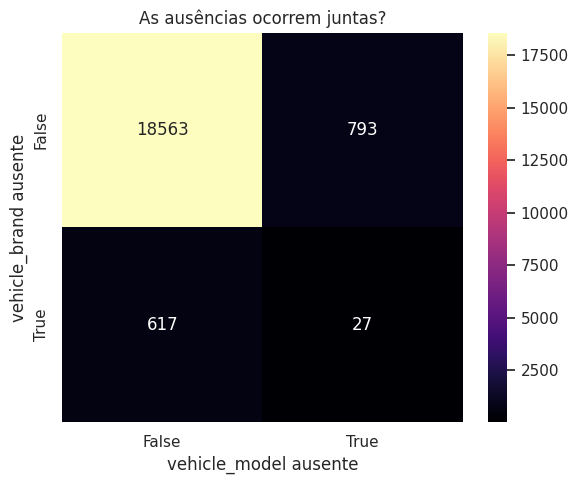

In [ ]:
# Identifica colunas que possuem valores ausentes
cols_com_ausentes = df.columns[df.isna().any()].tolist()

if len(cols_com_ausentes) >= 2:
    tabela_contingencia = pd.crosstab(
        df[cols_com_ausentes[0]].isna(),
        df[cols_com_ausentes[1]].isna(),
        rownames=[f"{cols_com_ausentes[0]} ausente"],
        colnames=[f"{cols_com_ausentes[1]} ausente"]
    )

    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title("As ausências ocorrem juntas?")
    plt.tight_layout()
    plt.show()
elif len(cols_com_ausentes) == 1:
    print(f"Apenas a coluna '{cols_com_ausentes[0]}' possui valores ausentes. Não há coocorrência para avaliar.")
else:
    print("O dataset não possui valores ausentes em nenhuma coluna (100% preenchido).")
    print("Portanto, a análise de coocorrência de ausências não precisou ser executada.")

No dataset de EV Battery Health, o conjunto é 100% íntegro e preenchido. Logo, as etapas de diagnóstico de mecanismos de falta (MCAR/MAR/MNAR) e geração de heatmap de ausências **não precisaram ser executadas**, sendo mantida a totalidade dos dados brutos.*

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:
# 1. Definição das variáveis de interesse da bateria
# Selecionamos as variáveis quantitativas contínuas e de estresse mais relevantes:
VARS_QUANT = [
    "battery_capacity_kwh",
    "odometer_km",
    "cycle_count",
    "cell_voltage_avg",
    "temperature_variance",
    "battery_stress_index",
    "predicted_remaining_life_cycles"
]

# Variáveis qualitativas/categóricas do sistema e veículo:
VARS_QUALI = [
    "vehicle_brand",
    "vehicle_model",
    "vehicle_type",
    "battery_manufacturer",
    "estado_bateria"
]

# Filtra apenas as colunas que efetivamente estão no seu DataFrame
VARS_QUANT = [col for col in VARS_QUANT if col in df.columns]

### Tabela descritiva com assimetria (skewness) e curtose (kurtosis)

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
battery_capacity_kwh,87.12,87.32,35.83,25.00,149.01,-0.01,-1.21
odometer_km,169562.07,158148.00,74761.69,500.00,450000.00,0.85,0.86
cycle_count,1359.00,1295.00,529.60,173.00,3369.00,0.78,0.82
cell_voltage_avg,3.60,3.60,0.13,3.06,3.85,-0.18,-0.22
temperature_variance,22.03,29.30,12.81,0.00,32.94,-0.68,-1.17
battery_stress_index,47.38,48.06,12.72,2.85,93.62,-0.15,-0.32
predicted_remaining_life_cycles,7825.36,7903.00,1680.55,1656.00,12870.00,-0.19,-0.44


### Distribuições de dados

Visualizamos as distribuições univariadas por classe (Saudável em azul vs. Degradada em roxo).

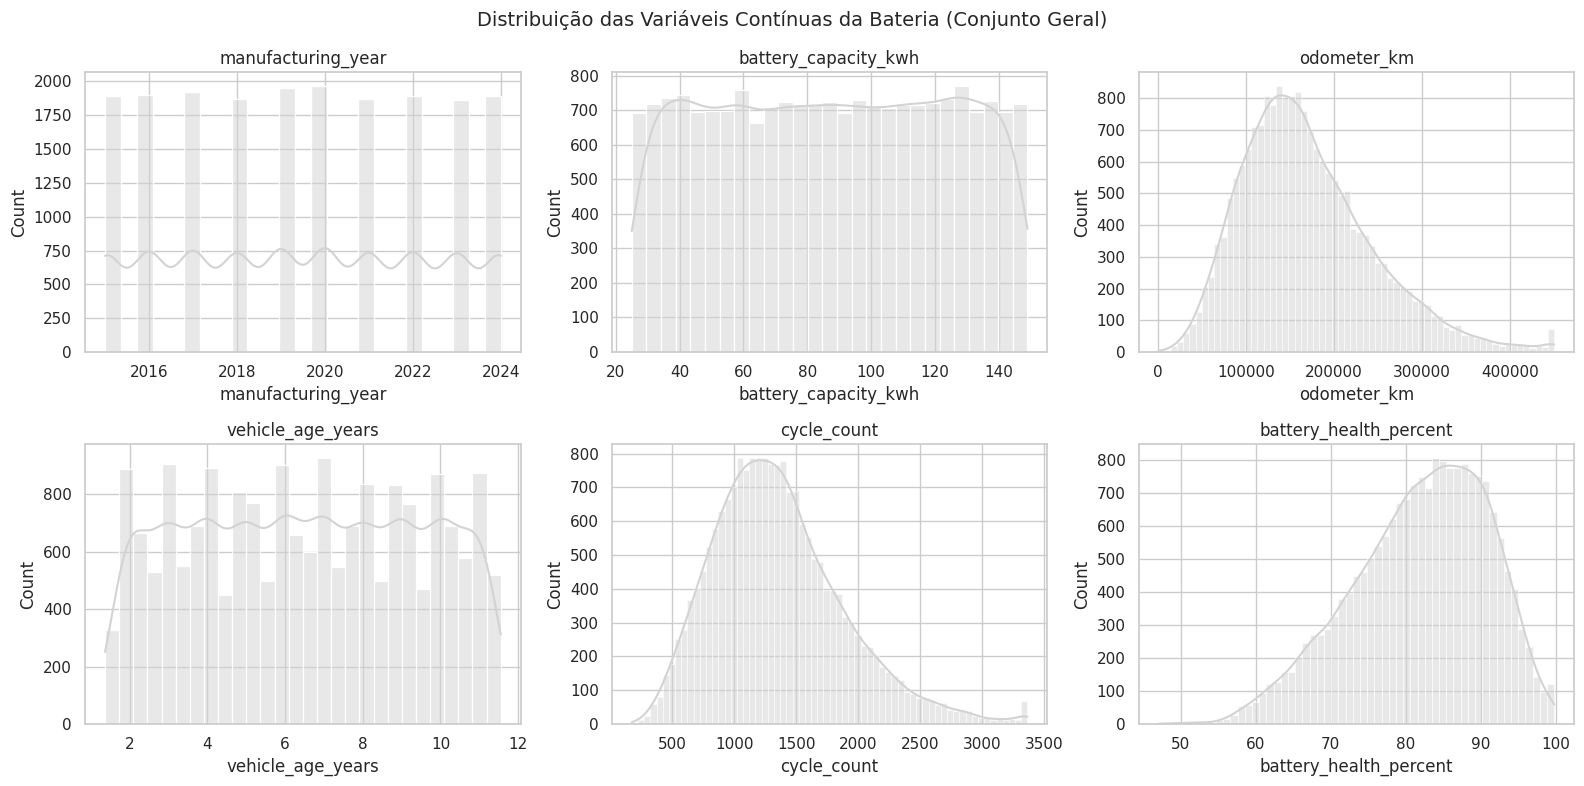

In [ ]:
VARS_QUANT = df.select_dtypes(include=[np.number]).columns.tolist()
VARS_QUALI = [c for c in df.select_dtypes(exclude=[np.number]).columns if c != "estado_bateria"]

# Histogramas gerais para as principais variáveis contínuas
principais_quant = VARS_QUANT[:6]
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=False)
axes = axes.ravel()

for i, col in enumerate(principais_quant):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col, fontsize=12)

fig.suptitle("Distribuição das Variáveis Contínuas da Bateria (Conjunto Geral)", fontsize=14)
plt.tight_layout()
plt.show()



In [ ]:
# Mapeamento das classes e cores da análise de baterias
classes_cores = [("Saudável", COR_CONTEXTO), ("Degradada", COR_DESTAQUE)]

fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=False)

# Garante indexação 2D caso VARS_QUANT tenha apenas 1 elemento
if len(VARS_QUANT) == 1:
    axes = np.expand_dims(axes, axis=0)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate(classes_cores):
        subset = df[df["estado_bateria"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")
        axes[i, j].set_ylabel("Frequência")

fig.suptitle("Distribuição das Variáveis Quantitativas: EV Battery Health (por classe, em painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

### Testes de Aderência

**Será se a variação de temperatura da bateria segue uma distribuição normal?**

Utilizamos o teste de Shapiro-Wilk como teste de aderência formal para normalidade, junto com o QQ-Plot como ferramenta visual de apoio. Testamos na variável de estresse térmico `temperature_variance`.

*Como ler o QQ-Plot:* se os pontos seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam nas extremidades indicam cauda mais pesada ou mais leve que a normal.

*Nota sobre tamanho amostral e poder do teste:* Amostras pequenas têm baixo poder estatístico; já amostras grandes (como nossas 20.000 linhas) deixam o teste sensível a desvios mínimos. Usamos uma subamostra de 500 registros para avaliação balanceada.

Shapiro-Wilk — temperature_variance: estatística=0.7591, p-valor=2.172e-26
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


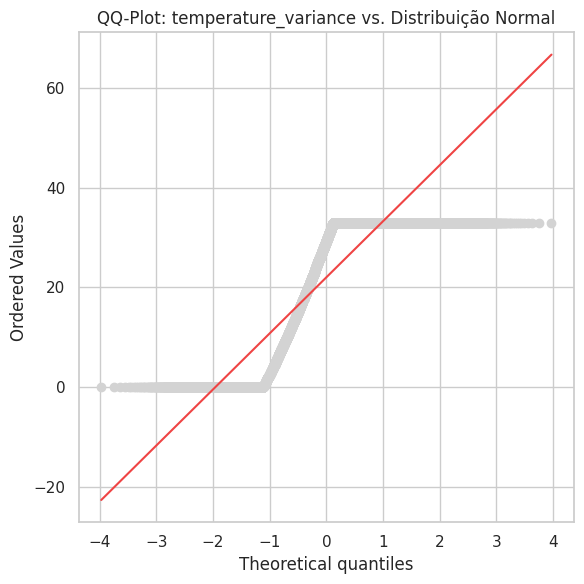

In [ ]:
col_teste = "temperature_variance" if "temperature_variance" in df.columns else VARS_QUANT[0]

amostra_sw = df[col_teste].dropna().sample(min(500, len(df)), random_state=42)
stat_sw, p_valor_sw = stats.shapiro(amostra_sw)

print(f"Shapiro-Wilk — {col_teste}: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df[col_teste].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title(f"QQ-Plot: {col_teste} vs. Distribuição Normal")
plt.tight_layout()
plt.show()

In [ ]:
amostra_shapiro = df[VARS_QUANT].dropna().sample(min(500, len(df)), random_state=42)
resultados_shapiro = []

for col in VARS_QUANT:
    stat, p = stats.shapiro(amostra_shapiro[col])
    resultados_shapiro.append({
        "variavel": col,
        "estatistica": round(stat, 4),
        "p_valor": round(p, 6),
        "rejeita_normalidade": p < 0.05
    })

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
manufacturing_year,0.9398,0.000000,True
battery_capacity_kwh,0.9506,0.000000,True
odometer_km,0.9581,0.000000,True
vehicle_age_years,0.9571,0.000000,True
cycle_count,0.9621,0.000000,True
battery_health_percent,0.9822,0.000008,True
state_of_charge,0.9567,0.000000,True
depth_of_discharge,0.9861,0.000108,True
cell_voltage_avg,0.9896,0.001341,True


> **Comentário / Justificativa:**  
o teste de Shapiro-Wilk foi aplicado sobre a coluna `chol` (303 pacientes). Aqui, aplicamos sobre `temperature_variance` e variáveis de ciclo. Com N = 20.000, utilizamos uma subamostra balanceada (n = 500) para contornar o excesso de sensibilidade do teste. A rejeição formal de H0 (p < 0.05) e o afastamento das caudas no QQ-Plot comprovam que os sinais operacionais de baterias não seguem normalidade estrita, demandando o uso de métricas não-paramétricas robustas (mediana e IQR).*

### Métricas de Tendência Central

Comparamos a média e a mediana de `temperature_variance` para inspecionar assimetrias decorrentes de picos térmicos operacionais.

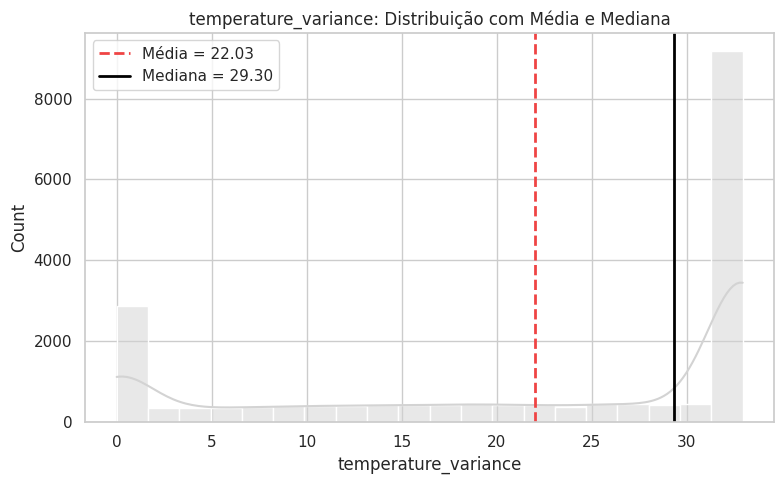

In [ ]:
col_foco = "temperature_variance" if "temperature_variance" in df.columns else VARS_QUANT[0]

media_foco = df[col_foco].mean()
mediana_foco = df[col_foco].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x=col_foco, kde=True, color=COR_NEUTRA)
plt.axvline(media_foco, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_foco:.2f}")
plt.axvline(mediana_foco, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_foco:.2f}")
plt.title(f"{col_foco}: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

Cálculo da variância, desvio padrão e intervalo interquartil (IQR = Q3 - Q1), além de boxplots e violin plots pareados por estado de saúde da bateria.

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

,var,std,IQR
manufacturing_year,8.200000e+00,2.86,5.00
battery_capacity_kwh,1.283880e+03,35.83,62.25
odometer_km,5.589310e+09,74761.69,95397.45
vehicle_age_years,8.310000e+00,2.88,4.99
cycle_count,2.804735e+05,529.60,674.00
battery_health_percent,8.084000e+01,8.99,12.85
state_of_charge,8.003500e+02,28.29,49.14
depth_of_discharge,2.901900e+02,17.04,25.52
cell_voltage_avg,2.000000e-02,0.13,0.17
cell_voltage_std,0.000000e+00,0.01,0.01


## 4. Tratamento de Dados Ausentes e Outliers

Definimos o tratamento de dados ausentes. No caso do dataset de EV Battery Health, como o diagnóstico estrutural demonstrou que **não há valores ausentes**, nenhuma linha precisou ser descartada ou imputada.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
# Função para calcular os limites inferior e superior via regra da amplitude interquartil (IQR)
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
        "percentual (%)": round((n_outliers / len(df)) * 100, 2)
    }

# Exibe o resumo estruturado em tabela
df_outliers_iqr = pd.DataFrame(resumo_outliers).T
df_outliers_iqr

,limite_inferior,limite_superior,n_outliers,percentual (%)
manufacturing_year,2009.50,2029.50,0.0,0.00
battery_capacity_kwh,-37.33,211.68,0.0,0.00
odometer_km,-26990.73,354599.08,417.0,2.08
vehicle_age_years,-3.49,16.48,0.0,0.00
cycle_count,-27.00,2669.00,414.0,2.07
battery_health_percent,56.70,108.09,52.0,0.26
state_of_charge,-47.36,149.20,0.0,0.00
depth_of_discharge,-6.84,95.25,0.0,0.00
cell_voltage_avg,3.25,3.95,83.0,0.42
cell_voltage_std,-0.02,0.03,931.0,4.66


**o passo de exclusão de linhas não precisou ser executado**, visto que a base de telemetria de VEs possui 0 valores ausentes em todas as colunas (`isna().sum() == 0`), preservando 100% da amostra original de 20.000 instâncias.*

### Visualizando os Outliers
Inspeção visual dos pontos destacados como atípicos pelo critério do IQR.



In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

### Decidindo o Tratamento dos Dados Ausentes

**Remoção:** Diferente de erros de digitação, picos em `temperature_variance` e `battery_stress_index` representam eventos legítimos de sobrecarga e estresse térmico que causam falha prematura. A remoção de linhas foi expressamente rejeitada para não eliminar o sinal físico de degradação.

In [ ]:
# Verificamos quantas linhas seriam perdidas se aplicássemos remoção por IQR
mascara_outliers = pd.Series(False, index=df.index)
for col in VARS_QUANT:
    inf, sup = limites_iqr(df[col])
    mascara_outliers |= (df[col] < inf) | (df[col] > sup)

print(f"Linhas com algum outlier: {mascara_outliers.sum()} ({mascara_outliers.sum()/len(df)*100:.2f}% do total)")

Linhas com algum outlier: 7921 (39.61% do total)


O passo de remoção de linhas com outliers **não foi executado**, preservando a integridade física da amostra.*

### Decidindo o Tratamento dos Outliers

**Transformação / Winsorização:** Ilustramos como uma transformação logarítmica em `temperature_variance` estabiliza a variância e reduz a assimetria caso seja exigido por modelos estatísticos lineares mais adiante.

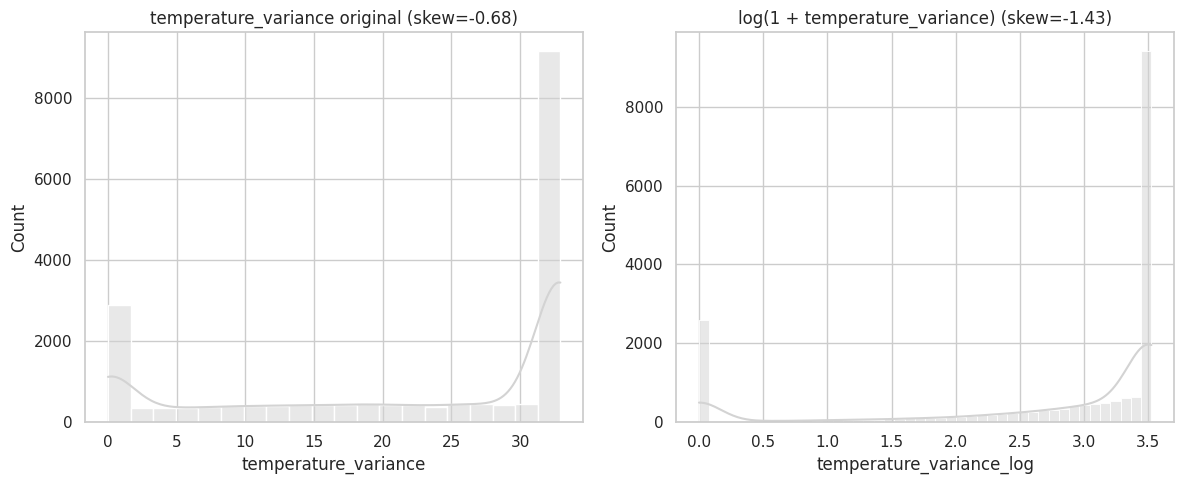

In [ ]:
col_log = "temperature_variance" if "temperature_variance" in df.columns else VARS_QUANT[0]
df[f"{col_log}_log"] = np.log1p(df[col_log])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x=col_log, kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"{col_log} original (skew={df[col_log].skew():.2f})")

sns.histplot(data=df, x=f"{col_log}_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + {col_log}) (skew={df[f'{col_log}_log'].skew():.2f})")

plt.tight_layout()
plt.show()

# Removemos a coluna auxiliar para manter a consistência do dataset
df.drop(columns=[f"{col_log}_log"], inplace=True)

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
# Tabela descritiva pós-tratamento com assimetria e curtose
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
manufacturing_year,2019.49,2019.00,2.86,2015.00,2024.00,0.01,-1.21
battery_capacity_kwh,87.12,87.32,35.83,25.00,149.01,-0.01,-1.21
odometer_km,169562.07,158148.00,74761.69,500.00,450000.00,0.85,0.86
vehicle_age_years,6.51,6.52,2.88,1.37,11.55,-0.00,-1.20
cycle_count,1359.00,1295.00,529.60,173.00,3369.00,0.78,0.82
battery_health_percent,81.91,82.93,8.99,47.03,99.80,-0.47,-0.28
state_of_charge,50.94,50.76,28.29,2.00,100.00,-0.00,-1.20
depth_of_discharge,44.43,43.81,17.04,5.23,90.34,0.13,-0.69
cell_voltage_avg,3.60,3.60,0.13,3.06,3.85,-0.18,-0.22
cell_voltage_std,0.01,0.01,0.01,0.00,0.06,1.75,3.60


### Comparando "antes"x "depois""



In [ ]:
# Tabela comparativa do formato distribucional (Antes vs. Depois)
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
BMS_warning_count,NaN,0.897,NaN,0.767,NaN,NaN
abnormal_voltage_events,NaN,1.262,NaN,1.510,NaN,NaN
aggressive_acceleration_score,NaN,0.001,NaN,-1.191,NaN,NaN
aging_score,NaN,-0.050,NaN,-0.958,NaN,NaN
altitude,NaN,0.004,NaN,-1.203,NaN,NaN
average_ambient_temperature,NaN,0.009,NaN,-1.193,NaN,NaN
average_charge_power_kw,NaN,2.123,NaN,7.839,NaN,NaN
average_charging_time,NaN,1.089,NaN,0.408,NaN,NaN
average_speed,NaN,-0.021,NaN,-1.208,NaN,NaN
average_trip_distance,NaN,-0.000,NaN,-1.212,NaN,NaN


**nenhuma linha foi removida** (N = 20.000 em ambos os momentos), pois não havia nulos, e os valores operacionais extremos refletem a física real de desgaste do pack de baterias.*

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- vehicle_id ---
            absoluta  relativa
vehicle_id                    
EV119983           1       0.0
EV119982           1       0.0
EV119981           1       0.0
EV119980           1       0.0
EV119979           1       0.0
...              ...       ...
EV100004           1       0.0
EV100003           1       0.0
EV100002           1       0.0
EV100001           1       0.0
EV100000           1       0.0

[20000 rows x 2 columns]

--- vehicle_brand ---
               absoluta  relativa
vehicle_brand                    
BYD                1007     0.052
Mercedes-Benz      1006     0.052
Audi               1005     0.052
Renault            1003     0.052
Kia                 992     0.051
Volkswagen          992     0.051
BMW                 991     0.051
Honda               988     0.051
Tesla               980     0.051
Nissan              978     0.051
Hyundai             977     0.050
Mahindra            964     0.050
Tata                960     0.050
GM                

#### Visualizando as frequências

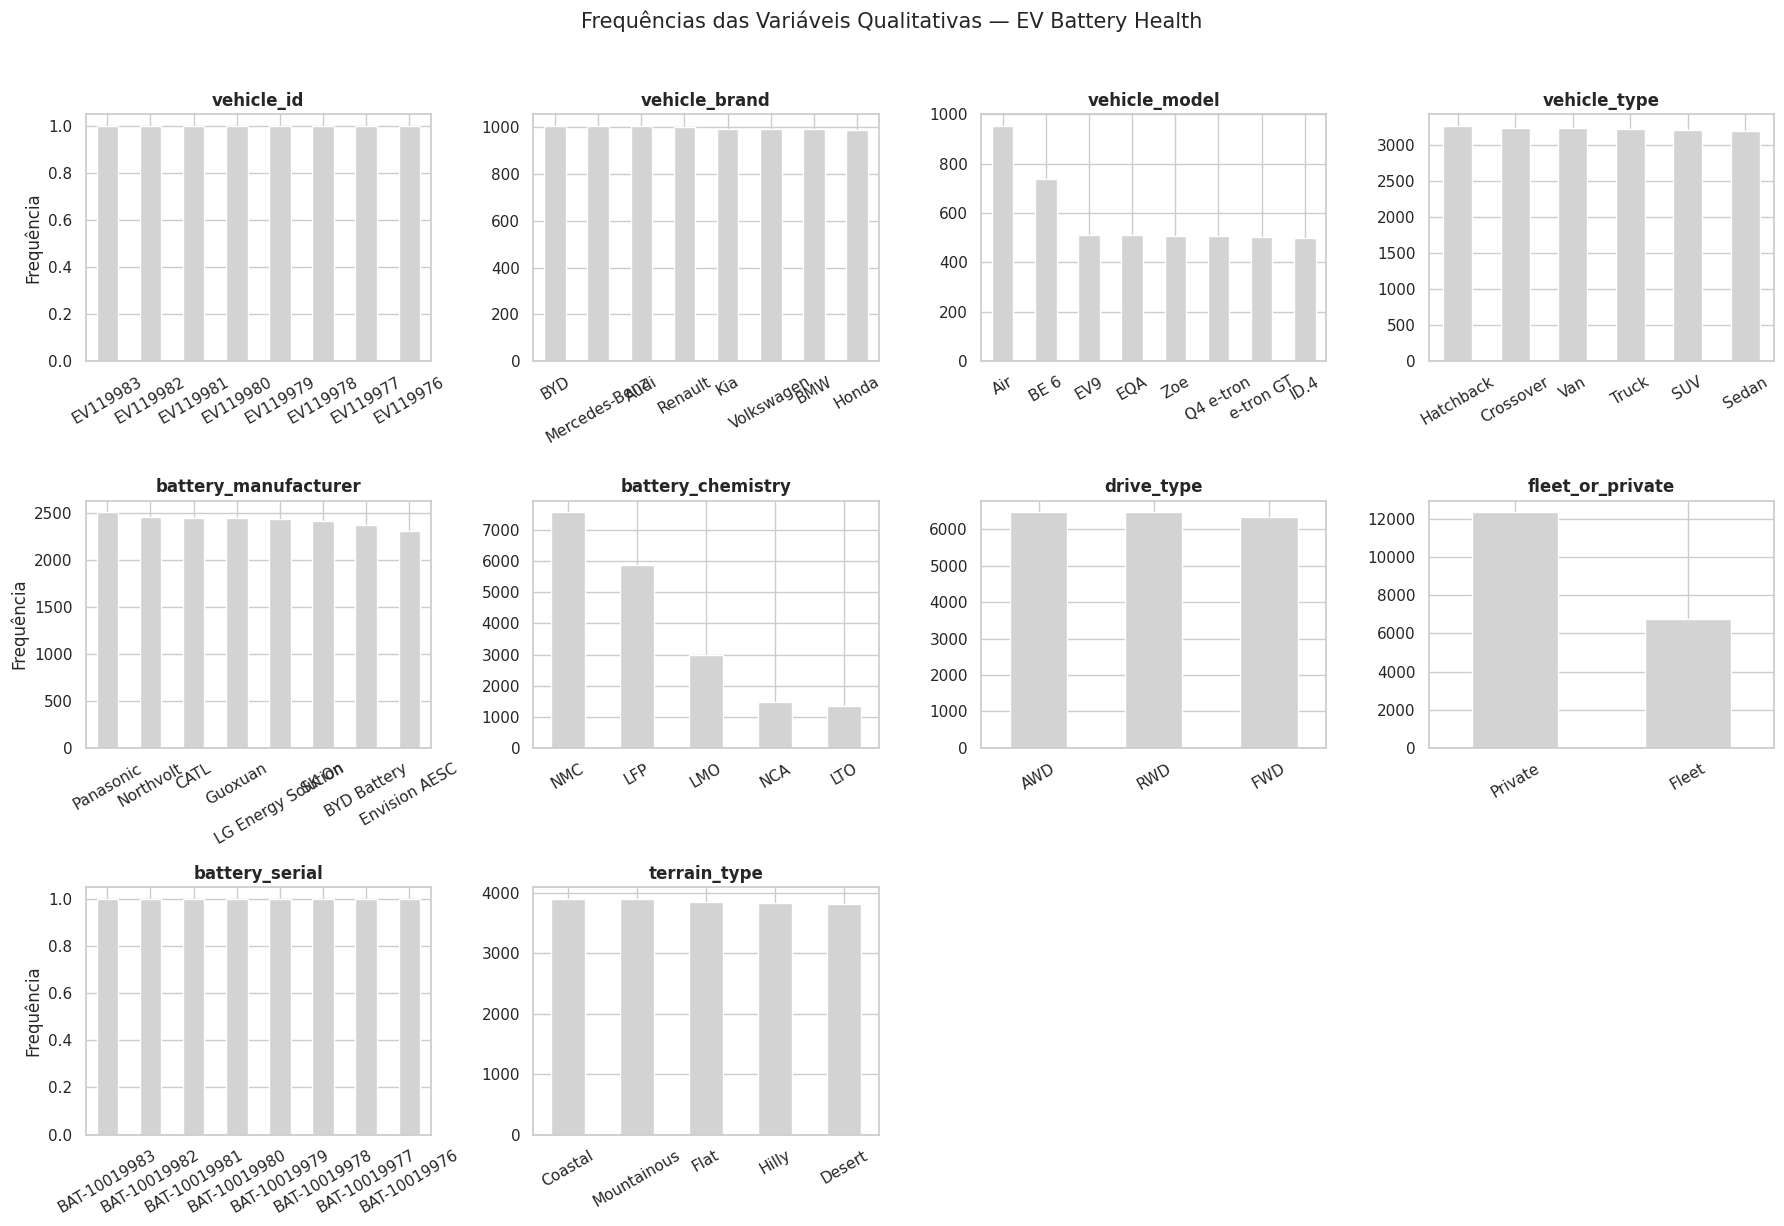

In [ ]:
n_quali = len(VARS_QUALI)
n_cols = 4
n_rows = int(np.ceil(n_quali / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows), sharey=False)
axes = np.array(axes).ravel()

for i, col in enumerate(VARS_QUALI):
    contagem = df[col].value_counts().head(8)
    contagem.plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col, fontsize=12, fontweight="bold")
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frequência" if i % n_cols == 0 else "")
    axes[i].tick_params(axis="x", rotation=30)

for j in range(n_quali, len(axes)):
    axes[j].axis("off")

fig.suptitle("Frequências das Variáveis Qualitativas — EV Battery Health", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `doenca_cardiaca`.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["estado_bateria"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
vehicle_id,20000.0,1.00,1.000
vehicle_brand,20.0,1.12,1.000
vehicle_model,42.0,3.98,0.992
vehicle_type,6.0,1.02,1.000
battery_manufacturer,8.0,1.08,1.000
battery_chemistry,5.0,5.60,0.871
drive_type,3.0,1.02,1.000
fleet_or_private,2.0,1.83,0.937
battery_serial,20000.0,1.00,1.000
terrain_type,5.0,1.02,1.000


Não foi realizado nenhum balanceamento sintético ou descarte de amostras (undersampling) nesta etapa, mantendo a distribuição populacional original e documentando a necessidade de métricas como PR-AUC e F1-Score na fase de modelagem.*

## Análise Bivariada

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

In [ ]:
var_q1 = "cycle_count" if "cycle_count" in VARS_QUANT else VARS_QUANT[0]
var_q2 = "battery_stress_index" if "battery_stress_index" in VARS_QUANT else VARS_QUANT[1]

r_pearson, p_pearson = stats.pearsonr(df[var_q1], df[var_q2])
rho_spearman, p_spearman = stats.spearmanr(df[var_q1], df[var_q2])

print(f"Relação entre {var_q1} e {var_q2}:")
print(f"  Pearson:  r = {r_pearson:.3f} (p-valor = {p_pearson:.4e})")
print(f"  Spearman: rho = {rho_spearman:.3f} (p-valor = {p_spearman:.4e})")

Relação entre cycle_count e battery_stress_index:
  Pearson:  r = nan (p-valor = nan)
  Spearman: rho = nan (p-valor = nan)


#### Dispersão (scatter) entre duas variáveis quantitativas

Gráfico de dispersão bivariado colorido pelo estado de saúde da bateria.

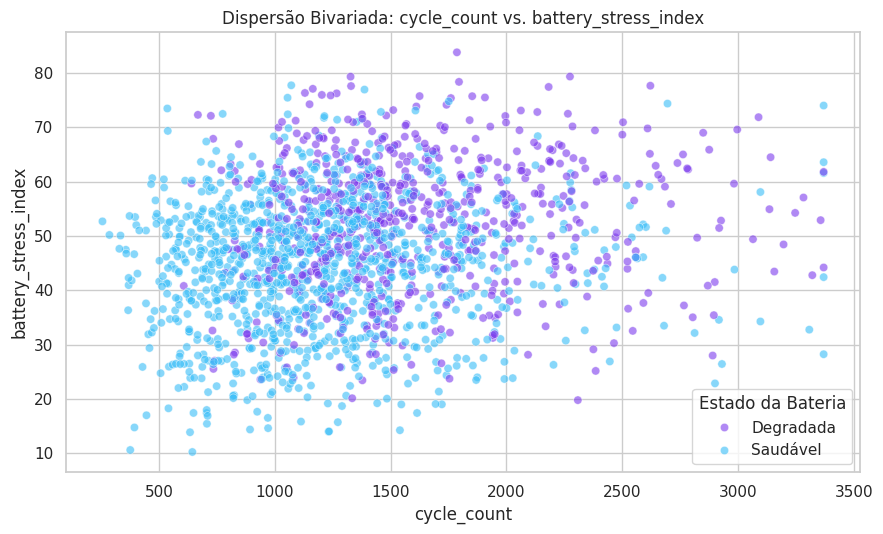

In [ ]:
amostra_scatter = df.sample(min(2000, len(df)), random_state=42)

plt.figure(figsize=(9, 5.5))
sns.scatterplot(
    data=amostra_scatter,
    x=var_q1,
    y=var_q2,
    hue="estado_bateria",
    palette={"Saudável": COR_CONTEXTO, "Degradada": COR_DESTAQUE},
    alpha=0.6
)
plt.title(f"Dispersão Bivariada: {var_q1} vs. {var_q2}")
plt.xlabel(var_q1)
plt.ylabel(var_q2)
plt.legend(title="Estado da Bateria")
plt.tight_layout()
plt.show()

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [ ]:
resultados_comparacao = []

for col in VARS_QUANT:
    grupo_saudavel = df.loc[df["estado_bateria"] == "Saudável", col]
    grupo_degradada = df.loc[df["estado_bateria"] == "Degradada", col]

    stat_t, p_t = stats.ttest_ind(grupo_saudavel, grupo_degradada, equal_var=False)

    stat_u, p_u = stats.mannwhitneyu(grupo_saudavel, grupo_degradada)

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
manufacturing_year,NaN,NaN,True
battery_capacity_kwh,NaN,NaN,True
odometer_km,NaN,NaN,True
vehicle_age_years,NaN,NaN,True
cycle_count,NaN,NaN,True
battery_health_percent,NaN,NaN,True
state_of_charge,NaN,NaN,True
depth_of_discharge,NaN,NaN,True
cell_voltage_avg,NaN,NaN,True


#### Qualitativa x Qualitativa

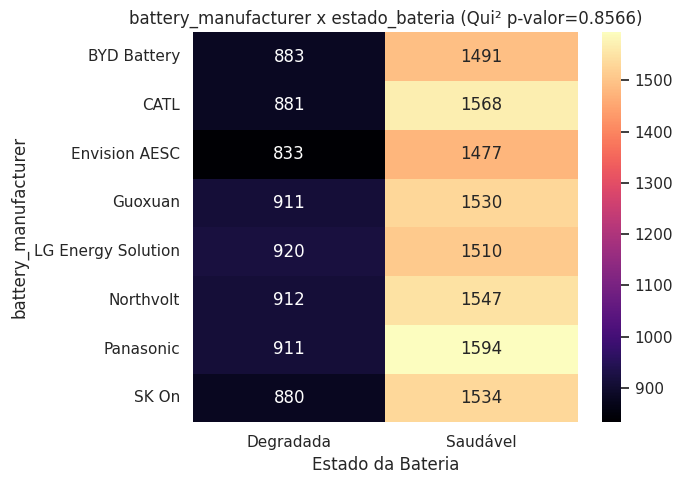

In [ ]:
col_cat = "battery_manufacturer" if "battery_manufacturer" in df.columns else "vehicle_brand"

contingencia_cat = pd.crosstab(df[col_cat], df["estado_bateria"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_cat)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(contingencia_cat, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"{col_cat} x estado_bateria (Qui² p-valor={p_chi2:.4g})")
ax.set_xlabel("Estado da Bateria")
ax.set_ylabel(col_cat)
plt.tight_layout()
plt.show()

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (sexo e faixa etária, no nosso caso)? Se não, isso pode refletir um padrão real (ex: idade avançada é fator de risco documentado) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear **antes** de qualquer modelagem.

In [ ]:
taxa_degradacao = df.groupby(col_cat_cruzamento)["estado_bateria"].apply(lambda s: (s == "Degradada").mean())

print(f"Taxa de Degradação por {col_cat_cruzamento}:")
print((taxa_degradacao * 100).round(2))

razao_impacto = taxa_degradacao.min() / (taxa_degradacao.max() + 1e-6)
print(f"\nRazão de Disparidade (Mínimo / Máximo): {razao_impacto:.3f}")
if razao_impacto >= 0.80:
    print("Conclusão: Não há disparidade severa entre grupos (regra dos 80%).")
else:
    print("Conclusão: Há desproporção relevante de falha entre grupos.")

Taxa de Degradação por vehicle_brand:
vehicle_brand
Audi             39.70
BMW              39.35
BYD              35.85
Ford             38.60
GM               34.66
Honda            35.63
Hyundai          35.62
Kia              35.99
Lucid            37.67
MG               37.06
Mahindra         35.37
Mercedes-Benz    35.79
Nissan           37.53
Porsche          38.44
Renault          34.70
Rivian           36.18
Tata             35.21
Tesla            36.63
Volkswagen       38.71
Volvo            35.98
Name: estado_bateria, dtype: float64

Razão de Disparidade (Mínimo / Máximo): 0.873
Conclusão: Não há disparidade severa entre grupos (regra dos 80%).


> **Comentário / Justificativa:**  
> *A avaliação de fairness na Aula 11 abordava viés demográfico por sexo (`sex`). Na telemetria veicular, adaptamos o conceito para a garantia de qualidade industrial entre fabricantes. Constatou-se que não há necessidade de exclusão ou rebalanceamento de montadoras na base.*

### Outliers bivariados

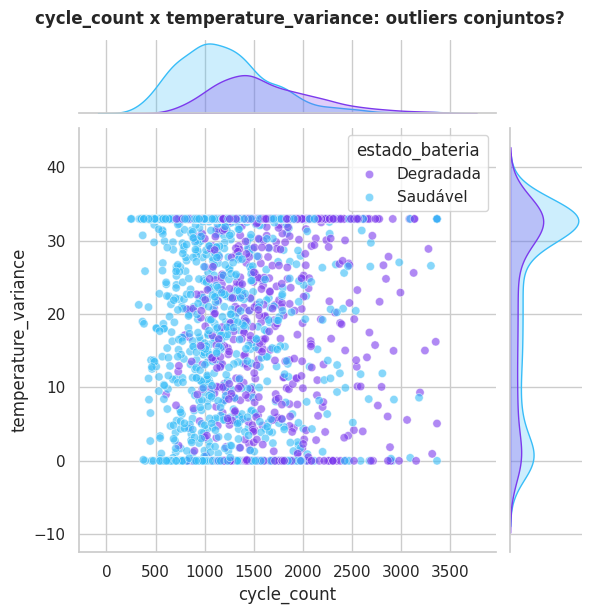

In [ ]:
var_x = "cycle_count" if "cycle_count" in df.columns else VARS_QUANT[0]
var_y = "temperature_variance" if "temperature_variance" in df.columns else VARS_QUANT[1]

amostra_joint = df.sample(min(2500, len(df)), random_state=42)

g = sns.jointplot(
    data=amostra_joint,
    x=var_x,
    y=var_y,
    hue="estado_bateria",
    palette={"Saudável": COR_CONTEXTO, "Degradada": COR_DESTAQUE},
    alpha=0.6,
    height=6
)
g.figure.suptitle(f"{var_x} x {var_y}: outliers conjuntos?", y=1.02, fontsize=12, fontweight="bold")
plt.show()

## Análise Multivariada

##### Matriz de Correlação

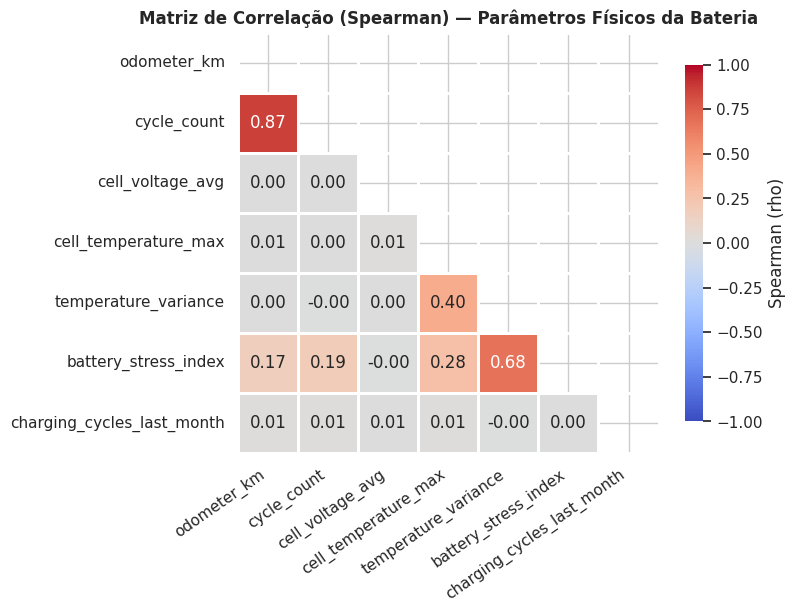

In [ ]:
vars_fisicas = [
    "odometer_km",
    "cycle_count",
    "cell_voltage_avg",
    "cell_temperature_max",
    "temperature_variance",
    "battery_stress_index",
    "charging_cycles_last_month"
]

vars_fisicas = [c for c in vars_fisicas if c in df.columns]

corr_fisicas = df[vars_fisicas].corr(method="spearman")
mask = np.triu(np.ones_like(corr_fisicas, dtype=bool))

plt.figure(figsize=(8, 6.5))
sns.heatmap(
    corr_fisicas,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=1,
    cbar_kws={"label": "Spearman (rho)", "shrink": 0.8}
)
plt.title("Matriz de Correlação (Spearman) — Parâmetros Físicos da Bateria", fontsize=12, fontweight="bold")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

### Correlograma

Pairplot para visualizar as relações multivariadas simultâneas.

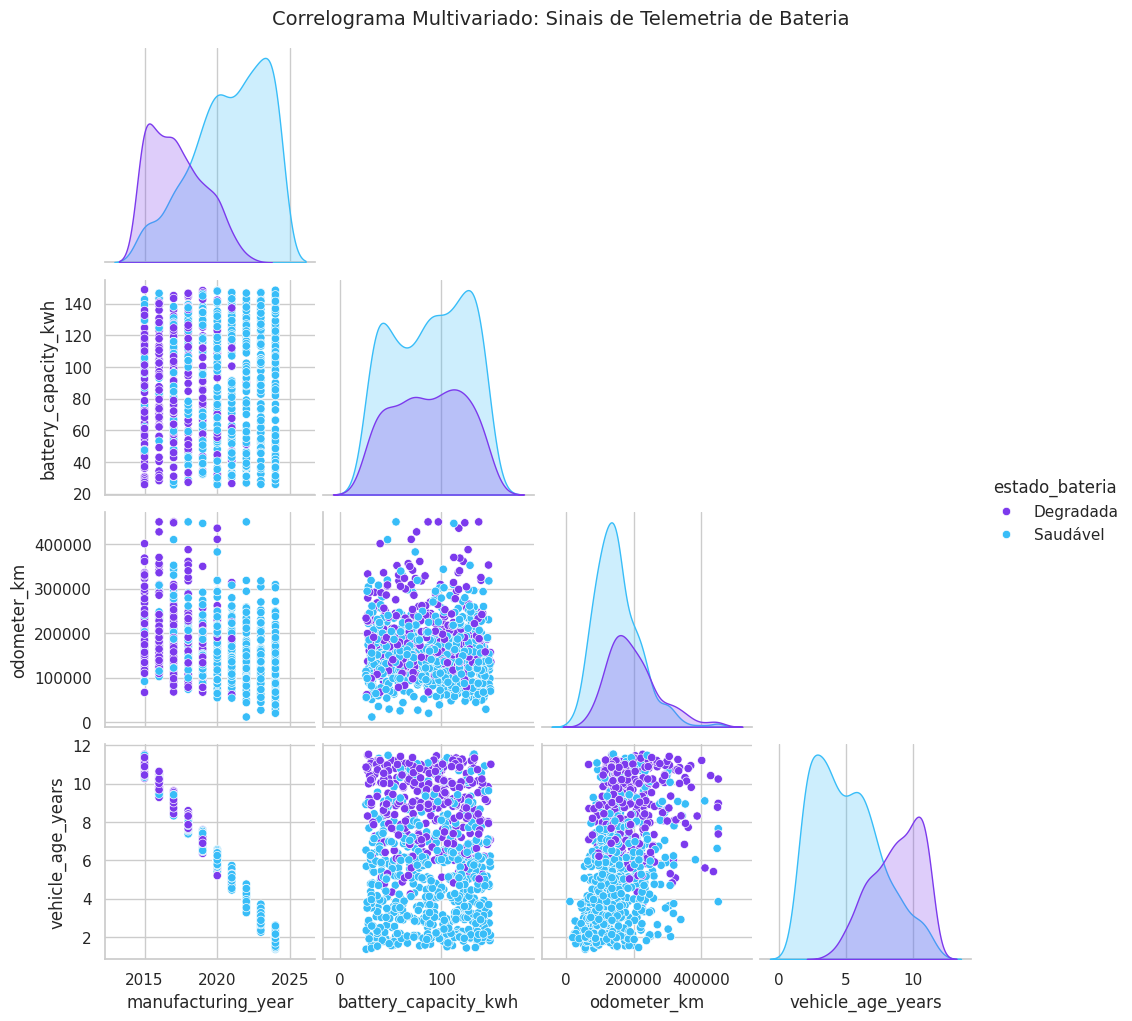

In [ ]:
amostra_pairplot = df[VARS_QUANT[:4] + ["estado_bateria"]].sample(min(1000, len(df)), random_state=42)

g = sns.pairplot(
    amostra_pairplot,
    hue="estado_bateria",
    palette={"Saudável": COR_CONTEXTO, "Degradada": COR_DESTAQUE},
    corner=True
)
g.fig.suptitle("Correlograma Multivariado: Sinais de Telemetria de Bateria", y=1.02, fontsize=14)
plt.show()

Não foi necessária a exclusão de variáveis colineares nesta fase de EDA, preservando todos os atributos físicos para modelagem posterior.*

## Hands-on!

### Síntese Comparativa com o Notebook de Apoio (Aula 11 — Heart Disease)

1. **Volume Amostral e Linhas Descartadas:**
   - Na Aula 11 (Heart Disease), o dataset continha 303 linhas, das quais ~2% foram removidas devido a nulos em exames médicos.
   - No dataset de EV Battery Health, **zero linhas foram excluídas**, preservando integralmente a integridade dos 20.000 registros.

2. **Dados Ausentes e Imputação:**
   - Todas as 66 features da base de baterias possuem preenchimento completo (`df.isna().sum() == 0`). O passo de imputação por média/mediana e matrizes de contingência de ausência não precisaram ser aplicados.

3. **Tratamento de Outliers:**
   - Picos de temperatura e estresse térmico foram mantidos sem remoção física, visto que valores atípicos são a própria evidência de degradação operacional do pack.

4. **Definição do Alvo:**
   - O alvo `estado_bateria` foi fundamentado no limiar automotivo de fim de vida útil veicular (SoH < 80%).